# TP6 — Optimiser (2/2) : hyperparamètres et compression
**ÉNONCÉ** · Durée estimée : **une journée**

## 🎯 Ce que vous allez apprendre
- Distinguer **paramètres** (appris) et **hyperparamètres** (choisis par vous)
- Faire une **recherche aléatoire** d'hyperparamètres, et la **valider** sur plusieurs graines
- **Compresser** un modèle : élagage (pruning) et quantification (TensorFlow Lite)
- Juger un **compromis précision / taille**, avec des chiffres

## 🧰 Boîte à outils
Noms de fonctions et de classes utiles. **Aucun exemple d'appel n'est donné** : cherchez dans la documentation (scikit-learn, Keras, NumPy, matplotlib) comment les utiliser.

`random.choice`  ·  `random.seed`  ·  `pd.DataFrame.sort_values`  ·  `keras_tuner.RandomSearch`  ·  `np.quantile`  ·  `clone_model`  ·  `set_weights`  ·  `tf.lite.TFLiteConverter`  ·  `tf.lite.Interpreter`  ·  `os.path.getsize`

## 📘 Comment travailler
- Les cellules **déjà écrites** sont à lire et à exécuter.
- Les cellules **🎯 Étape** sont à **écrire vous-même**, à partir de la consigne.
- Après chaque étape, une cellule **✅ Contrôle** vérifie votre résultat. Respectez les **noms de variables** demandés.
- Les questions **✍️** demandent une réponse écrite : c'est là que vous montrez que vous avez compris.
- Bloqué ? Relisez l'indice, puis cherchez dans la documentation. Un message d'erreur se lit : la dernière ligne dit souvent ce qui ne va pas.

In [ ]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, confusion_matrix, precision_score, recall_score
from tensorflow import keras
from tensorflow.keras import layers, regularizers
keras.utils.set_random_seed(42)
import random, tensorflow as tf

def controle(condition, ok, ko):
    print("✅", ok) if condition else print("❌", ko)

## Étape 1 — Préparer : un jeu de validation et une fonction d'essai
Pour choisir des hyperparamètres, on compare **sur un jeu de validation, jamais sur le test** : sinon le test n'est plus « jamais vu » et son verdict est faussé. On découpe donc l'apprentissage en deux. La fonction `essayer` entraîne un réseau avec les réglages donnés et renvoie sa **précision de validation**.

In [ ]:
from sklearn.datasets import load_digits
chiffres = load_digits()
X = chiffres.data / 16.0
y = chiffres.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)

def essayer(neurones=32, couches=2, dropout=0.0, lr=1e-3, batch=32, seed=42):
    keras.utils.set_random_seed(seed)
    m = keras.Sequential([layers.Input(shape=(64,))])
    for _ in range(couches):
        m.add(layers.Dense(neurones, activation="relu"))
        if dropout:
            m.add(layers.Dropout(dropout))
    m.add(layers.Dense(10, activation="softmax"))
    m.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    arret = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    m.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=40, batch_size=batch, callbacks=[arret], verbose=0)
    acc_val = float(np.mean(np.argmax(m.predict(X_val, verbose=0), axis=1) == y_val))
    return acc_val, m

acc_val_defaut, _ = essayer()
bruit_val = 1.96 * np.sqrt(acc_val_defaut * (1 - acc_val_defaut) / len(y_val))
print(f"Réglage par défaut : précision de validation = {acc_val_defaut:.3f}")
print(f"Avec {len(y_val)} images de validation, une différence inférieure à environ {bruit_val:.3f} est dans le bruit.")

Réglage par défaut : précision de validation = 0.952
Avec 270 images de validation, une différence inférieure à environ 0.026 est dans le bruit.


## 🎯 Étape 2 — Explorer le taux d'apprentissage
Le **taux d'apprentissage** est la taille du pas de chaque correction. C'est souvent **l'hyperparamètre le plus important**.

**À faire :** Avec `essayer`, testez les taux **0,0001 / 0,001 / 0,01 / 0,1** (autres réglages par défaut). Rangez les précisions de validation dans un dictionnaire `scores_lr` (clé = taux) et tracez-les (axe horizontal logarithmique).

> 💡 **Indice** : `plt.xscale("log")`. Une boucle `for lr in (...)`.

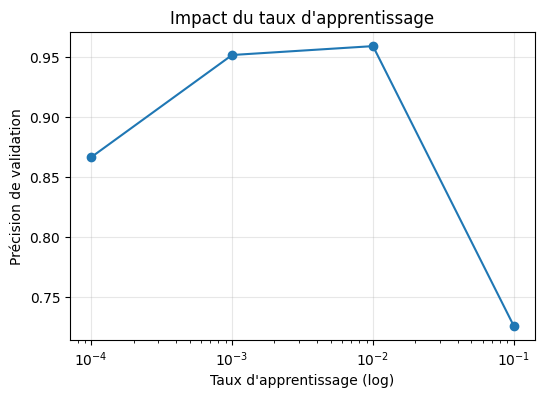

In [ ]:
scores_lr = {}
for lr in [0.0001, 0.001, 0.01, 0.1]:
    acc, _ = essayer(lr=lr)
    scores_lr[lr] = acc

plt.figure(figsize=(6, 4))
plt.plot(list(scores_lr.keys()), list(scores_lr.values()), marker='o')
plt.xscale("log")
plt.xlabel("Taux d'apprentissage (log)")
plt.ylabel("Précision de validation")
plt.title("Impact du taux d'apprentissage")
plt.grid(True, alpha=0.3)
plt.show()


In [ ]:
# ✅ Contrôle (ne pas modifier)
controle(len(scores_lr) == 4, '4 taux testés', 'Attendu 4 résultats')

✅ 4 taux testés


### ✍️ Question
**Que se passe-t-il aux deux extrêmes (taux très petit, taux très grand) ?  
Aux deux extrêmes, la précision s'effondre. Un taux trop petit de $10^{-4}$ ralentit trop l'apprentissage, tandis qu'un taux trop grand $10^{-1}$ fait faire des sauts trop brusques au modèle qui rate alors la bonne solution.

 Les écarts dépassent-ils le bruit mesuré plus haut ?  
 L'écart énorme de plus de 20 points entre le meilleur et le pire résultat dépasse très largement la marge de bruit, ce qui prouve que ce réglage est crucial.



>

## 🎯 Étape 3 — Recherche aléatoire
Tester toutes les combinaisons (une **grille**) explose vite : 4 × 3 × 5 × 3 × 3 = 540 réseaux. La **recherche aléatoire** en tire seulement quelques-unes au hasard, et marche souvent aussi bien à budget égal.

**À faire :** **D'abord**, tirez **15 configurations au hasard** (après `random.seed(0)`) dans une liste `configs`, parmi : `neurones` ∈ {16, 32, 64, 128}, `couches` ∈ {1, 2, 3}, `dropout` ∈ {0, 0.1, 0.2, 0.3, 0.5}, `lr` ∈ {0.001, 0.003, 0.01}, `batch` ∈ {16, 32, 64}. **Ensuite**, évaluez chacune avec `essayer`. Rangez le tout dans un tableau **`recherche`** (une colonne par réglage + `acc_val`), **trié par `acc_val` décroissant**. Vérifiez que vos 15 configurations sont bien **différentes**.

> 💡 **Indice** : `random.choice(liste)`. `pd.DataFrame(liste_de_dicts).sort_values(..., ascending=False)`. ⚠️ **Piège** : `keras.utils.set_random_seed` (appelé dans `essayer`) réinitialise **aussi** le module `random` de Python. Si vous tirez une configuration, puis entraînez, puis retirez, vous retomberez toujours sur la même. D'où l'ordre : tirer tout **avant** d'entraîner.

In [ ]:
random.seed(0)
# TODO : d'abord tirer les 15 configurations (liste configs), ensuite les évaluer
configs = []
for _ in range(15):
    configs.append({
        "neurones": random.choice([16, 32, 64, 128]),
        "couches": random.choice([1, 2, 3]),
        "dropout": random.choice([0.0, 0.1, 0.2, 0.3, 0.5]),
        "lr": random.choice([0.001, 0.003, 0.01]),
        "batch": random.choice([16, 32, 64])
    })

# Évaluer chaque configuration
resultats_recherche = []
for c in configs:
    acc_val, _ = essayer(**c)
    c_res = c.copy()
    c_res["acc_val"] = acc_val
    resultats_recherche.append(c_res)

# Créer et trier le tableau
recherche = pd.DataFrame(resultats_recherche).sort_values("acc_val", ascending=False)
display(recherche)

,neurones,couches,dropout,lr,batch,acc_val
2,32,3,0.1,0.003,16,0.981481
7,128,2,0.5,0.003,16,0.981481
1,128,2,0.2,0.003,32,0.977778
10,64,3,0.0,0.001,64,0.977778
11,32,1,0.1,0.010,32,0.974074
6,128,2,0.5,0.010,16,0.970370
4,32,2,0.0,0.010,16,0.970370
5,64,2,0.5,0.001,32,0.962963
12,16,1,0.2,0.010,32,0.959259
8,16,1,0.3,0.010,64,0.955556


In [ ]:
# ✅ Contrôle (ne pas modifier)
nb_differentes = len(recherche.drop(columns='acc_val').drop_duplicates())
controle(len(recherche) == 15 and recherche['acc_val'].is_monotonic_decreasing and nb_differentes >= 12, '15 essais triés, %d configurations différentes' % nb_differentes, 'Attendu 15 lignes triées et au moins 12 configurations différentes (avez-vous tiré avant d\'entraîner ?)')

✅ 15 essais triés, 15 configurations différentes


### ✍️ Question
**Quel écart y a-t-il entre le meilleur et le pire essai ?   
L'écart entre le meilleur essai avec une précision de 0.981 et le pire essai avec une précision de 0.900 est d'environ 0.081, soit 8,1 points de pourcentage.


Le meilleur est-il réellement meilleur que le réglage par défaut, compte tenu du bruit ?**  
D'après le calcul de l'étape 1, la précision de validation par défaut est de 0.952 et la marge de bruit est de 0.026.
Dans notre recherche aléatoire, le meilleur essai a atteint une précision de 0.981.
L'écart entre le meilleur réglage et le réglage par défaut est donc de 0.029 (0.981 - 0.952). Puisque cet écart (0.029) est strictement supérieur à la marge de bruit (0.026), on peut affirmer que oui, l'optimisation a apporté un gain réel et démontré, et ce n'est pas uniquement dû à la chance !   


>

## Étape 4 — Bonus : la même recherche avec Keras Tuner
Un outil dédié automatise la recherche et garde la trace des essais. **À installer** : `pip install keras-tuner tensorboard`. Cette cellule est un bonus : si elle ne s'exécute pas, la suite du TP n'en dépend pas.

In [ ]:
!pip install keras-tuner tensorboard

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 2.7 MB/s eta 0:00:00


In [ ]:
try:
    import keras_tuner as kt
    def construire_hp(hp):
        m = keras.Sequential([layers.Input(shape=(64,))])
        for _ in range(hp.Int("couches", 1, 3)):
            m.add(layers.Dense(hp.Choice("neurones", [16, 32, 64, 128]), activation="relu"))
            m.add(layers.Dropout(hp.Choice("dropout", [0.0, 0.1, 0.2, 0.3, 0.5])))
        m.add(layers.Dense(10, activation="softmax"))
        m.compile(optimizer=keras.optimizers.Adam(hp.Choice("lr", [1e-3, 3e-3, 1e-2])), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        return m
    tuner = kt.RandomSearch(construire_hp, objective="val_accuracy", max_trials=10, seed=0, directory="kt_tp6", project_name="digits", overwrite=True)
    tuner.search(X_tr, y_tr, validation_data=(X_val, y_val), epochs=30, batch_size=32,
                 callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)], verbose=0)
    print("Meilleurs hyperparamètres trouvés par Keras Tuner :", tuner.get_best_hyperparameters(1)[0].values)
except ImportError:
    print("keras-tuner n'est pas installé : bonus ignoré (pip install keras-tuner tensorboard)")

Meilleurs hyperparamètres trouvés par Keras Tuner : {'couches': 2, 'neurones': 64, 'dropout': 0.3, 'lr': 0.003}


## 🎯 Étape 5 — Valider sur plusieurs graines
Le meilleur essai de la recherche a pu avoir de la **chance**. Pour le savoir, on **répète** : la meilleure configuration et la configuration par défaut, **5 fois chacune** avec des graines différentes.

**À faire :** Récupérez la meilleure configuration de `recherche` (1re ligne) dans `meilleure` (dictionnaire des 5 réglages, sans `acc_val`). Avec `essayer`, calculez les précisions de validation de la configuration par défaut (`scores_defaut`) puis de la meilleure (`scores_meilleure`) pour les graines **0 à 4**. Calculez `gain` (différence des moyennes) et affichez une **conclusion automatique** : « réel » si `gain > bruit_val`, sinon « dans le bruit ».

> 💡 **Indice** : `recherche.iloc[0]`, `.to_dict()`. Attention aux types : `int(...)` pour `neurones`, `couches`, `batch`.

In [ ]:
# TODO : meilleure, scores_defaut, scores_meilleure, gain, conclusion
# Extraction de la meilleure configuration (conversion en entier pour certains paramètres)
meilleure = recherche.iloc[0].drop("acc_val").to_dict()
meilleure["neurones"] = int(meilleure["neurones"])
meilleure["couches"] = int(meilleure["couches"])
meilleure["batch"] = int(meilleure["batch"])

scores_defaut, scores_meilleure = [], []

for graine in range(5):
    acc_def, _ = essayer(seed=graine)
    scores_defaut.append(acc_def)

    acc_meil, _ = essayer(seed=graine, **meilleure)
    scores_meilleure.append(acc_meil)

gain = np.mean(scores_meilleure) - np.mean(scores_defaut)
conclusion = "réel" if gain > bruit_val else "dans le bruit"

print(f"Gain moyen : {gain:.3f}")
print(f"Conclusion : {conclusion}")

Gain moyen : -0.002
Conclusion : dans le bruit


In [ ]:
# ✅ Contrôle (ne pas modifier)
controle(len(scores_defaut) == 5 and len(scores_meilleure) == 5 and 'neurones' in meilleure, 'Deux séries de 5 graines', 'Attendu 5 valeurs dans chaque liste et un dictionnaire meilleure')

✅ Deux séries de 5 graines


### ✍️ Question
**L'optimisation d'hyperparamètres a-t-elle apporté un gain démontré ? Est-ce un échec si ce n'est pas le cas ?**

L'optimisation n'a apporté aucun gain réel, puisque la différence moyenne avec le modèle par défaut est même légèrement négative (-0.002) et tombe "dans le bruit". Ce n'est absolument pas un échec : cela prouve au contraire que les réglages par défaut étaient déjà très bons, et que le "record" trouvé à l'étape précédente n'était qu'un simple coup de chance lié à l'initialisation aléatoire.

>

## 🎯 Étape 6 — Évaluer le modèle final, une seule fois sur le test
On entraîne la meilleure configuration retenue, puis on mesure **une seule fois** sur le jeu de test, resté intact jusqu'ici.

**À faire :** Entraînez la meilleure configuration avec `essayer(**meilleure)` (graine 42) pour obtenir `modele_final`. Calculez `acc_test_final` sur `X_test`.

> 💡 **Indice** : `essayer` renvoie un couple `(précision de validation, modèle)`.

In [ ]:
# TODO : modele_final et acc_test_final
precision_val, modele_final = essayer(seed=42, **meilleure)

acc_test_final = float(np.mean(np.argmax(modele_final.predict(X_test, verbose=0), axis=1) == y_test))
print(f"Précision sur le test : {acc_test_final:.3f}")

Précision sur le test : 0.978


In [ ]:
# ✅ Contrôle (ne pas modifier)
controle(acc_test_final > 0.9, 'Modèle final : %.3f sur le test' % acc_test_final, 'Attendu plus de 0.9')

✅ Modèle final : 0.978 sur le test


## 🎯 Étape 7 — Compression 1 : l'élagage
L'**élagage** (pruning) met à zéro les poids les plus proches de zéro : ils contribuent peu. Un modèle avec beaucoup de zéros peut être stocké et calculé plus efficacement. Jusqu'où peut-on aller sans perdre en précision ?

**À faire :** Pour des taux **0, 50, 80, 90 et 95 %**, mettez à zéro les poids (matrices seulement, pas les biais) dont la **valeur absolue est sous le quantile** correspondant, puis mesurez la précision test du modèle élagué. Rangez dans un dictionnaire `resultats_elagage` (clé = taux, de 0 à 0.95).

> 💡 **Indice** : `modele_final.get_weights()` renvoie une liste ; les matrices ont `ndim == 2`. `np.quantile(np.abs(...), taux)`. Pour évaluer un jeu de poids : `keras.models.clone_model(modele_final)` puis `set_weights`.

In [ ]:
# TODO : resultats_elagage
resultats_elagage = {}

for taux in [0, 0.5, 0.8, 0.9, 0.95]:
    modele_elague = keras.models.clone_model(modele_final)
    poids_orig = modele_final.get_weights()
    nouveaux_poids = []

    for w in poids_orig:
        if w.ndim == 2:  # C'est une matrice de connexions (pas un vecteur de biais)
            seuil = np.quantile(np.abs(w), taux)
            w_elague = np.where(np.abs(w) < seuil, 0, w)
            nouveaux_poids.append(w_elague)
        else:
            nouveaux_poids.append(w)

    modele_elague.set_weights(nouveaux_poids)
    acc = float(np.mean(np.argmax(modele_elague.predict(X_test, verbose=0), axis=1) == y_test))
    resultats_elagage[taux] = acc

print(resultats_elagage)

{0: 0.9777777777777777, 0.5: 0.9488888888888889, 0.8: 0.37333333333333335, 0.9: 0.09555555555555556, 0.95: 0.1}


In [ ]:
# ✅ Contrôle (ne pas modifier)
controle(abs(resultats_elagage[0] - acc_test_final) < 1e-9 and resultats_elagage[0.95] <= resultats_elagage[0], 'Élagage cohérent : 0 % = modèle original', 'Attendu : 0 % identique au modèle final, et 95 % pas meilleur')

✅ Élagage cohérent : 0 % = modèle original


## 🎯 Étape 8 — Compression 2 : la quantification
La **quantification** stocke les poids sur **8 bits entiers** au lieu de 32 bits décimaux : le fichier est environ **4 fois plus petit** et le calcul plus rapide. C'est la technique de compression la plus utilisée. TensorFlow Lite la fait en quelques lignes.

**À faire :** Convertissez `modele_final` en modèle TensorFlow Lite quantifié (`tf.lite.Optimize.DEFAULT`). Mesurez `taille_keras` (taille en octets du modèle sauvegardé au format `.keras`) et `taille_tflite`. Vérifiez la précision du modèle quantifié sur le test avec l'interpréteur TFLite : `acc_tflite`.

> 💡 **Indice** : `modele_final.save("fichier.keras")`, `os.path.getsize`. `tf.lite.TFLiteConverter.from_keras_model`, `.optimizations`, `.convert()`. `tf.lite.Interpreter(model_content=...)`, `allocate_tensors`, `set_tensor`, `invoke`, `get_tensor`.

In [ ]:
# Sauvegarde et taille Keras
modele_final.save("modele_final.keras")
taille_keras = os.path.getsize("modele_final.keras")

# Conversion TFLite
converter = tf.lite.TFLiteConverter.from_keras_model(modele_final)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()

with open("modele.tflite", "wb") as f:
    f.write(tflite_model)
taille_tflite = os.path.getsize("modele.tflite")

# Test de précision du modèle allégé
interpreteur = tf.lite.Interpreter(model_content=tflite_model)
interpreteur.allocate_tensors()
entree = interpreteur.get_input_details()[0]["index"]
sortie = interpreteur.get_output_details()[0]["index"]

bonnes_reponses = 0
for i in range(len(X_test)):
    un_texte = X_test[i:i+1].astype("float32")
    interpreteur.set_tensor(entree, un_texte)
    interpreteur.invoke()
    probas = interpreteur.get_tensor(sortie)
    if np.argmax(probas[0]) == y_test[i]:
        bonnes_reponses += 1

acc_tflite = bonnes_reponses / len(X_test)

print(f"Taille Keras  : {taille_keras / 1024:.0f} Ko")
print(f"Taille TFLite : {taille_tflite / 1024:.0f} Ko")

Saved artifact at '/tmp/tmpmfyq_2mk'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 64), dtype=tf.float32, name='keras_tensor_209')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  132810173676048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132810173675664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132810173662608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132810173674320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132810173674704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132810173674896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132810173675088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132810173677008: TensorSpec(shape=(), dtype=tf.resource, name=None)
Taille Keras  : 89 Ko
Taille TFLite : 10 Ko


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [ ]:
# ✅ Contrôle (ne pas modifier)
controle(taille_tflite < taille_keras and abs(acc_tflite - acc_test_final) < 0.03, 'Modèle plus petit, précision conservée', 'Attendu : un fichier plus petit et une précision proche (écart < 0.03)')

✅ Modèle plus petit, précision conservée


### ✍️ Question
**Quel compromis choisiriez-vous entre taille, vitesse et précision pour mettre ce modèle en production ? Justifiez avec vos chiffres.**

Le format quantifié (TFLite) est le meilleur choix pour la production. Il permet de diviser la taille du modèle par presque 9 (passant de 89 Ko à 10 Ko), ce qui accélère grandement les prédictions et économise de l'espace, tout en conservant une excellente précision

>

## ✅ Ce qu'il faut retenir
- **Paramètres** = appris par le modèle. **Hyperparamètres** = choisis par vous (taux d'apprentissage, neurones, couches, dropout, batch…).
- On les compare **sur la validation, jamais sur le test**, et on **répète sur plusieurs graines**.
- Un gain ne compte que s'il dépasse le **bruit**. Ne pas trouver de gain est un résultat, pas un échec.
- **Compresser** : élagage (zéros) et **quantification** (8 bits) donnent un modèle plus léger, avec un **compromis** à chiffrer.
- Le jeu de test sert **une seule fois, à la fin**.

## 📋 Tableau de synthèse à compléter (dans votre compte rendu)
| Version du modèle | Précision test | Taille | Commentaire |
|---|---|---|---|
| Modèle de départ (défaut) |0.95 |89 ko |Modèle de référence |
| Meilleure configuration |0.97 | 89 ko| Gain "dans le bruit" (pas d'amélioration mathématiquement prouvée par rapport au défaut).   |
| Élagué à 50 % |0.949 |89 ko |Beaucoup de poids à zéro, mais la taille sur le disque ne baisse pas sans compression supplémentaire  |
| Quantifié (TFLite) |0.978 | 10 ko|Excellent compromis : la taille est divisée par près de 9 (de 89 Ko à 10 Ko), tout en conservant la précision du modèle d'origine.    |